# EVCharge Intelligence — Member 2 temporal analysis

Analyze session-start demand and recorded energy using the verified Phase 2 tables. This notebook validates the cleaned data through existing functions, checks the saved summaries, and imports reusable plotting functions. It does not implement station/queue analysis or Power BI.

Methodological motivation: Baek, K., Lee, E., & Kim, J. (2024), [A dataset for multi-faceted analysis of electric vehicle charging transactions](https://doi.org/10.1038/s41597-024-02942-9), *Scientific Data*, 11, 262. The paper motivates examining charging transactions over time. Its dataset and numerical results are separate from ours. Session starts differ from connection/coupling profiles; calendar normalization and the relative demand index are project choices.

Source: generated synthetic Indian charging data; declared timezone Asia/Kolkata. Generator code, seed, sampling/loss assumptions and reuse licence were not supplied.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

current = Path.cwd().resolve()
ROOT = current if (current / "src/demand_analysis.py").is_file() else current.parent
if not (ROOT / "src/demand_analysis.py").is_file():
    raise RuntimeError("Open from the repository root or notebooks directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data_preparation import file_hash
from src.demand_analysis import analyze_sessions, WEEKDAYS, LOCATION_TYPES, CHARGER_TYPES, sensitivity_has_variation
from src.demand_visualization import load_analysis, generate_figures

summary_dir = ROOT / "outputs/demand"
protected = [ROOT / "data/raw/EV_Dataset_India.csv", ROOT / "data/processed/charging_sessions.csv",
             *sorted(summary_dir.glob("*.csv")), summary_dir / "analysis_summary.json"]
before = {path: file_hash(path) for path in protected}
tables, summary = load_analysis(summary_dir)
cleaned = pd.read_csv(ROOT / "data/processed/charging_sessions.csv", dtype=str, keep_default_na=False)
recomputed, checked_summary = analyze_sessions(cleaned)
for name, saved in tables.items():
    pd.testing.assert_frame_equal(saved, recomputed[name], check_dtype=False, rtol=1e-10, atol=1e-6)
assert checked_summary["reconciliation"]["all_passed"]
del cleaned, recomputed
print(f"Validated {summary['input_session_count']:,} sessions; all saved summaries agree with existing analysis functions.")

# Inline rendering is activated after the shared CLI plotting module is imported.
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib_inline.backend_inline import set_matplotlib_formats
from src.demand_visualization import style_axis, finish_figure, BLUE, ORANGE, GREEN
set_matplotlib_formats("png")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 10})


def show_inline(figure, note):
    try:
        finish_figure(figure, note)
        display(figure)
    finally:
        plt.close(figure)


Validated 200,000 sessions; all saved summaries agree with existing analysis functions.


## Calendar denominators and measurement eligibility

Accepted session starts span 01-01-2024 01:53 to 30-12-2025 23:53 in Asia/Kolkata, across 730 inclusive dates. Complete collection including zero-session dates is an assumption; timestamps do not establish uptime or complete boundary-day observation.

Three starts across two Fridays give 1.5 starts/Friday, compared with two starts on one Saturday giving 2/Saturday. Use the count of each group’s represented dates. Zero-session dates remain in the calendar.

Finite nonnegative energy is eligible. Plausibility checks are separate; charger-energy limits now use active duration, not port occupancy. Demand continues to count Session_Start, not Arrival_Time.

In [2]:
display(pd.DataFrame([{
    "sessions": summary["input_session_count"],
    "calendar_days": summary["coverage"]["inclusive_calendar_days"],
    "sessions_per_day": summary["avg_sessions_per_day"],
    "valid_energy_sessions": summary["valid_energy_session_count"],
    "invalid_energy_sessions": summary["invalid_energy_session_count"],
    "recorded_energy_kwh": summary["total_recorded_energy_kwh"],
}]).round(2))
display(tables["weekday_weekend_demand"][["Day_Type", "session_count", "calendar_days", "avg_sessions_per_day"]].round(2))
display(tables["monthly_demand"].loc[[0, 3, 15, 23], ["Year_Month", "calendar_days", "avg_sessions_per_day", "is_partial_boundary_month"]].round(2))
paths = generate_figures(tables, summary_dir / "figures")
print(f"Saved {len(paths)} charts as PNG only (300 dpi). The four additional analyses below include inline plotting code and outputs.")

,sessions,calendar_days,sessions_per_day,valid_energy_sessions,invalid_energy_sessions,recorded_energy_kwh
0,200000,730,273.97,200000,0,3014172.81


,Day_Type,session_count,calendar_days,avg_sessions_per_day
0,Weekday,144621,522,277.05
1,Weekend,55379,208,266.25


,Year_Month,calendar_days,avg_sessions_per_day,is_partial_boundary_month
0,2024-01,31,269.32,False
3,2024-04,30,305.87,False
15,2025-04,30,326.17,False
23,2025-12,30,282.27,True


Saved 10 charts as PNG only (300 dpi). The four additional analyses below include inline plotting code and outputs.


## Hourly session starts

![Hourly session starts](../outputs/demand/figures/01_hourly_demand.png)

Hourly demand is no longer nearly uniform: relative index 0.10560–2.06376. Hour 09 has the most starts (17,198; 23.56/calendar day), versus hour 01 (880; 1.21/day). This is the generated sample's pattern, not evidence of real congestion or actual Indian charging behavior.

## Daily starts and smoothing

![Daily session starts](../outputs/demand/figures/02_daily_demand.png)

Daily starts peak at 377 on 2025-04-02 and are lowest at 186 on 2024-09-28, 2024-10-15. The trailing 7-day mean requires seven observations; the first six values remain missing.

## Weekday and weekend demand

![Weekday comparisons](../outputs/demand/figures/03_weekday_demand.png)

Weekdays average 277.05 starts/day across 522 dates; weekends average 266.25 across 208 dates. Wednesday is highest (280.02/day); Saturday is lowest (265.68/day). Comparisons use each group's calendar denominator; no significance or causes are inferred.

## Weekday–hour pattern

![Weekday–hour heatmap](../outputs/demand/figures/04_day_hour_heatmap.png)

Weekday–hour rates range from 1.01 at Thursday 02:00 to 26.19 at Tuesday 09:00. Higher starts do not measure simultaneous occupancy or prove congestion.

## Monthly demand

![Monthly demand](../outputs/demand/figures/05_monthly_demand.png)

Monthly starts/day range from 220.93 in 2024-09 to 326.17 in 2025-04. Partial boundary months: 2025-12. Partial coverage is not a missing-data marker; the synthetic differences do not establish real seasonality or a causal trend.

## Recorded energy associated with session-start periods

![Recorded-energy profiles](../outputs/demand/figures/06_recorded_energy.png)

All 200,000 energy measurements are numerically valid: 3,014,172.81 kWh total, 15.07 kWh per valid-energy session. Monthly energy/day ranges from 3,327.97 kWh in 2024-09 to 4,929.07 kWh in 2025-04. Full energy belongs to the session-start period, not measured hourly grid load.

## Energy plausibility validation

Both existing plausibility flags are false for all 200,000 sessions; their union is zero. The sensitivity scenario therefore retains all energy and sessions. Reporting this validation result is more informative than plotting two coincident curves. The CSV comparison remains available for audit/Power BI; if future data have retained/excluded variation, the exporter includes that distinct comparison. Synthetic consistency does not verify real measurements.

In [3]:
sensitivity = tables["monthly_energy_sensitivity"]
flag_counts = pd.DataFrame.from_dict(summary["input_validation"]["plausibility_flags"], orient="index")
display(flag_counts)
print("Union excluded:", summary["input_validation"]["plausibility_union_count"])
if sensitivity_has_variation(sensitivity):
    from src.demand_visualization import plot_sensitivity
    figure = plot_sensitivity(sensitivity)
    try:
        display(figure)
    finally:
        plt.close(figure)
else:
    print("No retained/excluded plausibility contrast: validation result reported instead of a comparison chart.")

,true,false,not_evaluable
Energy_Exceeds_Battery_Capacity,0,200000,0
Energy_Exceeds_Nominal_Charger_Energy,0,200000,0


Union excluded: 0
No retained/excluded plausibility contrast: validation result reported instead of a comparison chart.


## Location-type hourly profiles

**Question and metric:** Which start hours dominate within each site category? The percentage denominator is all sessions in that location type, so each represented type sums to 100%; this compares profile shape rather than raw site volumes.

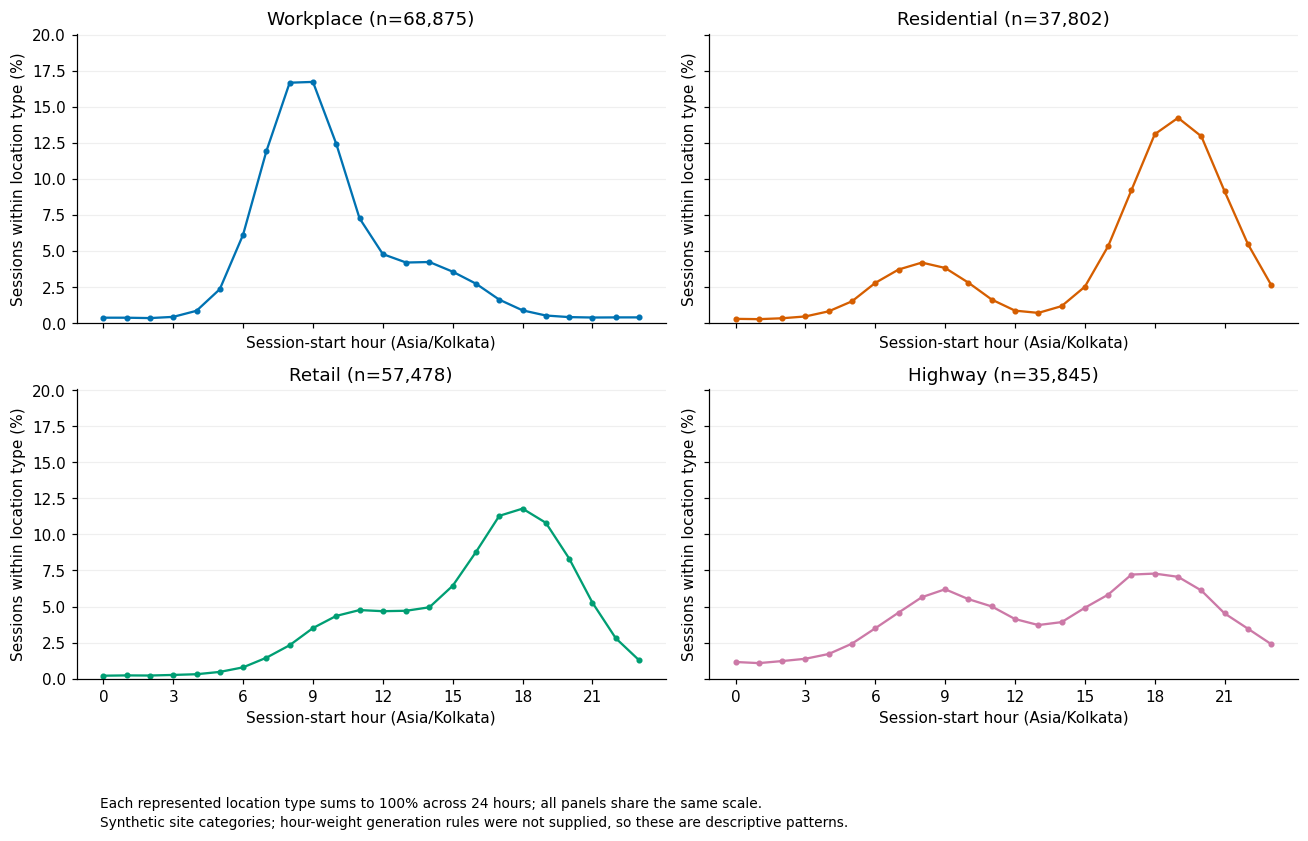

In [4]:
table = tables["location_type_hourly"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
colors = [BLUE, ORANGE, GREEN, "#CC79A7"]
ceiling = max(1, table.session_percentage.max() * 1.2)
for ax, location, color in zip(axes.flat, LOCATION_TYPES, colors):
    subset = table.loc[table.Location_Type.eq(location)]
    count = int(subset.location_session_count.iloc[0])
    ax.plot(subset.Charging_Hour, subset.session_percentage, color=color, marker="o", markersize=3)
    ax.set_title(f"{location} (n={count:,})")
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("Session-start hour (Asia/Kolkata)")
    style_axis(ax, "Sessions within location type (%)")
    ax.set_ylim(0, ceiling)
show_inline(fig, "Each represented location type sums to 100% across 24 hours; all panels share the same scale.\nSynthetic site categories; hour-weight generation rules were not supplied, so these are descriptive patterns.")

**Calculated findings:** Highway: 18:00, 7.28% (2,611/35,845 sessions); Residential: 19:00, 14.23% (5,378/37,802 sessions); Retail: 18:00, 11.79% (6,775/57,478 sessions); Workplace: 09:00, 16.72% (11,514/68,875 sessions).

**Interpretation and limitations:** Workplace/Residential/Retail/Highway are supplied synthetic site contexts. The morning Workplace and evening Residential/Retail peaks describe the CSV. Generator hourly weights were not provided, so no exact generation probabilities, real commuting behavior or causes are asserted.

## Weekday variability

**Question and metric:** How spread out are daily counts within each weekday? Use the existing full daily calendar, including zero-session dates. Boxes show linear-interpolated quartiles and median; whiskers extend to observations within 1.5 IQR.

,Weekday_Name,represented_days,q1_sessions,median_sessions,q3_sessions
0,Monday,105,247.00,277.0,307.00
1,Tuesday,105,253.00,278.0,296.00
2,Wednesday,104,252.75,277.0,308.25
3,Thursday,104,249.50,278.5,300.25
4,Friday,104,250.00,277.0,303.25
5,Saturday,104,237.00,266.5,291.25
6,Sunday,104,244.75,264.0,288.00


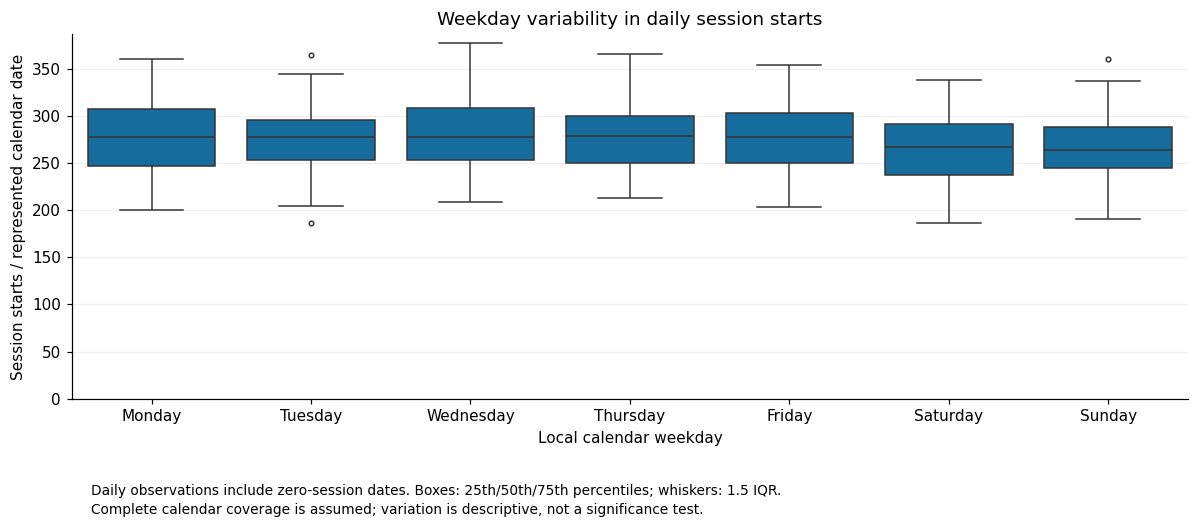

In [5]:
table = tables["daily_weekday_counts"]
display(tables["weekday_variability"][["Weekday_Name", "represented_days", "q1_sessions", "median_sessions", "q3_sessions"]].round(2))
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=table, x="Weekday_Name", y="session_count", order=WEEKDAYS,
            color=BLUE, ax=ax, fliersize=3)
ax.set_title("Weekday variability in daily session starts")
ax.set_xlabel("Local calendar weekday")
style_axis(ax, "Session starts / represented calendar date")
show_inline(fig, "Daily observations include zero-session dates. Boxes: 25th/50th/75th percentiles; whiskers: 1.5 IQR.\nComplete calendar coverage is assumed; variation is descriptive, not a significance test.")

**Calculated findings:** Daily medians: Monday 277, Tuesday 278, Wednesday 277, Thursday 278.5, Friday 277, Saturday 266.5, Sunday 264. Monday and Tuesday each have 105 represented dates; other weekdays have 104. Quartiles and counts are in weekday_variability.csv; zero dates are retained.

**Interpretation and limitations:** Calendar normalization removes unequal weekday representation; the boxplot exposes day-to-day spread rather than only group averages. Complete collection over the range is assumed, not measured uptime; no significance test is claimed.

## Time-period energy per session

**Question and metric:** Does energy per valid-energy session differ by start period? Non-overlapping local periods are Overnight [00,06), Morning [06,12), Afternoon [12,17), Evening [17,22), Late night [22,24). Whole energy is attributed to the start period, not grid load; unequal period lengths do not distort per-session averages.

,Time_Period,session_count,valid_energy_session_count,mean_energy_kwh,median_energy_kwh
0,Overnight,8855,8855,15.01,13.2
1,Morning,76931,76931,15.11,13.5
2,Afternoon,42513,42513,15.05,13.2
3,Evening,63634,63634,15.05,13.2
4,Late night,8067,8067,15.08,13.5


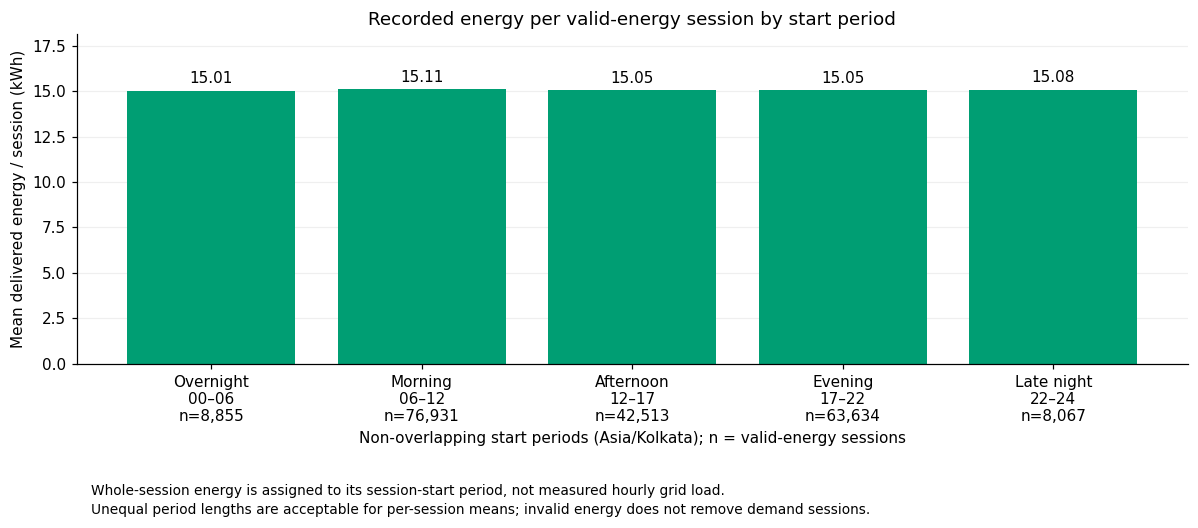

In [6]:
table = tables["time_period_energy"]
display(table[["Time_Period", "session_count", "valid_energy_session_count", "mean_energy_kwh", "median_energy_kwh"]].round(2))
fig, ax = plt.subplots(figsize=(11, 5))
labels = [f"{row.Time_Period}\n{row.start_hour_inclusive:02d}–{row.end_hour_exclusive:02d}\nn={row.valid_energy_session_count:,}"
          for row in table.itertuples()]
bars = ax.bar(labels, table.mean_energy_kwh, color=GREEN)
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_ylim(0, max(1, table.mean_energy_kwh.max()) * 1.2)
ax.set_title("Recorded energy per valid-energy session by start period")
ax.set_xlabel("Non-overlapping start periods (Asia/Kolkata); n = valid-energy sessions")
style_axis(ax, "Mean delivered energy / session (kWh)")
show_inline(fig, "Whole-session energy is assigned to its session-start period, not measured hourly grid load.\nUnequal period lengths are acceptable for per-session means; invalid energy does not remove demand sessions.")

**Calculated findings:** Mean/median kWh per valid-energy session: Overnight 15.01/13.20 (n=8,855); Morning 15.11/13.50 (n=76,931); Afternoon 15.05/13.20 (n=42,513); Evening 15.05/13.20 (n=63,634); Late night 15.08/13.50 (n=8,067).

**Interpretation and limitations:** Similar per-session energies coexist with different period session volumes. The simulation contract ties energy to battery/SOC quantities and active-power limits, not to our chart period labels. No time-of-day energy relationship was imposed by this analysis.

## Charger-type comparison

**Question and metric:** How do AC Slow, AC Fast and DC Fast differ? Energy (kWh), active duration (Charging_End minus start) and connected occupancy (Session_End minus start) are separate panels. Calculations check supplied duration fields and keep invalid energy out of energy metrics only.

,Charger_Type,session_count,mean_energy_kwh,median_energy_kwh,mean_active_charging_duration_min,mean_connected_duration_min
0,AC Slow,28764,15.07,13.2,274.19,352.48
1,AC Fast,94977,15.09,13.2,80.53,146.39
2,DC Fast,76259,15.05,13.2,29.76,48.23


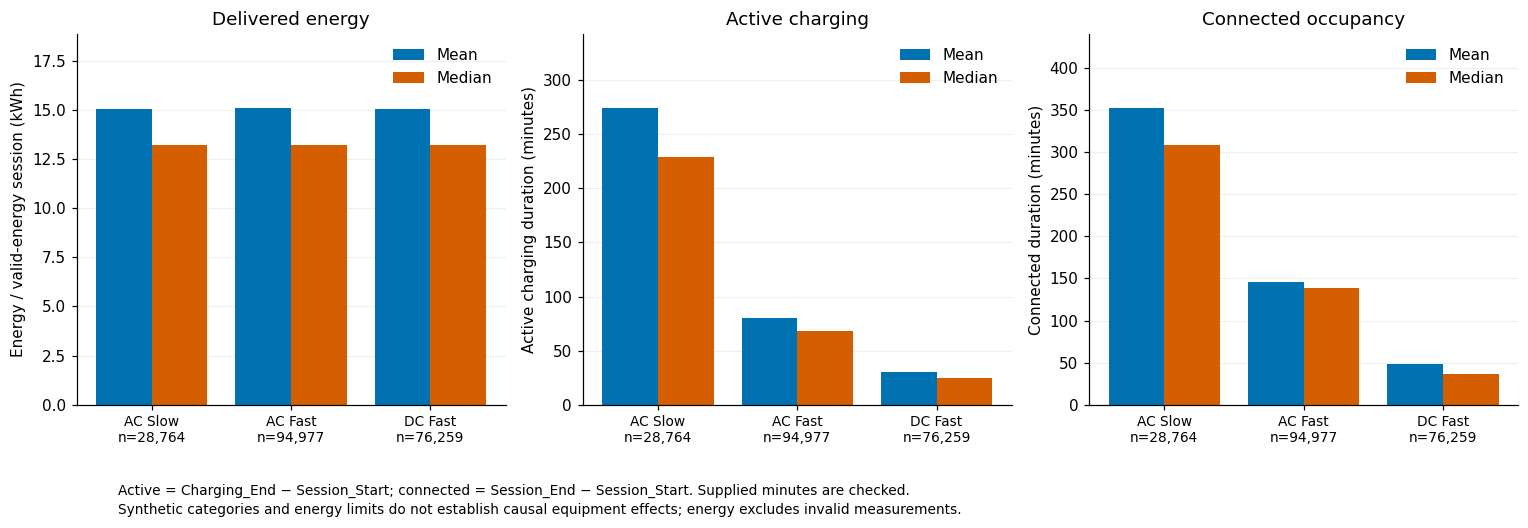

In [7]:
table = tables["charger_type_comparison"]
display(table[["Charger_Type", "session_count", "mean_energy_kwh", "median_energy_kwh", "mean_active_charging_duration_min", "mean_connected_duration_min"]].round(2))
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
x = pd.Series(range(len(table)))
labels = [f"{row.Charger_Type}\nn={row.session_count:,}" for row in table.itertuples()]
for ax, mean, median, title, units in [
    (axes[0], "mean_energy_kwh", "median_energy_kwh", "Delivered energy", "Energy / valid-energy session (kWh)"),
    (axes[1], "mean_active_charging_duration_min", "median_active_charging_duration_min", "Active charging", "Active charging duration (minutes)"),
    (axes[2], "mean_connected_duration_min", "median_connected_duration_min", "Connected occupancy", "Connected duration (minutes)"),
]:
    ax.bar(x - 0.2, table[mean], width=0.4, color=BLUE, label="Mean")
    ax.bar(x + 0.2, table[median], width=0.4, color=ORANGE, label="Median")
    ax.set_xticks(x, labels, fontsize=9)
    ax.set_title(title)
    style_axis(ax, units)
    ax.set_ylim(0, max(1, table[[mean, median]].max().max()) * 1.25)
    ax.legend(frameon=False)
show_inline(fig, "Active = Charging_End − Session_Start; connected = Session_End − Session_Start. Supplied minutes are checked.\nSynthetic categories and energy limits do not establish causal equipment effects; energy excludes invalid measurements.")

**Calculated findings:** AC Slow: n=28,764, mean energy 15.07 kWh, mean active 274.19 min, mean connected 352.48 min; AC Fast: n=94,977, mean energy 15.09 kWh, mean active 80.53 min, mean connected 146.39 min; DC Fast: n=76,259, mean energy 15.05 kWh, mean active 29.76 min, mean connected 48.23 min. Supplied active/connected duration mismatch counts are zero.

**Interpretation and limitations:** The documented synthetic contract separates active charging from post-charge occupancy and bounds energy by nominal power times active hours. Shorter DC Fast active times are consistent with that contract; similar energy means do not imply a causal charger effect or identical vehicle/sample composition.

## Limitations and Power BI handoff

The input is generated synthetic Indian charging data. Station mappings are internally consistent in this run, not independently verified locations. Generator code, seed, distribution/efficiency assumptions and reuse licence were not supplied. Keep arrivals, active charging and port occupancy separate. Counts alone do not prove congestion; port counts do not establish operational availability.

Use cleaned session-level data and a date table for interactive measures; keep fixed Python summaries as matching-filter references. Refresh removed fields, area/location filters, station-local ports and active/occupancy measures using docs/dataset_migration.md. No Power BI files are available to update here.

In [8]:
assert before == {path: file_hash(path) for path in protected}
assert not plt.get_fignums()
print("Inputs and all verified summary CSVs unchanged; four new inline charts displayed once each.")

Inputs and all verified summary CSVs unchanged; four new inline charts displayed once each.
